# EMSC 2019 – Parte 2/3: corpo cilíndrico excêntrico sobre placa em translação prescrita

**PME 3200 – Mecânica II (Escola Politécnica da USP)** — Exercício de Modelagem e Simulação Computacional.

**Enunciado (resumo).** O mesmo corpo rígido da Parte 1 (setor de disco homogêneo de centro $A$, raio $R$, massa $m$, centro de massa $G$ a uma
distância $e$ de $A$, $I_A=\tfrac12mR^2$, $I_G=m(\tfrac12R^2-e^2)$) **rola sem escorregar** sobre uma placa rígida $\mathcal P$ que executa, em relação
a um referencial inercial, uma **translação prescrita** com velocidade $\vec v=\dot x(t)\vec\imath+\dot y(t)\vec\jmath$, sendo

$$\dot x(t)=A_x\omega_x\sin(\omega_xt+\phi_x),\qquad \dot y(t)=A_y\omega_y\sin(\omega_yt+\phi_y).$$

A placa é imantada e um pequeno objeto de aço preso em $A$ produz uma força de atração vertical $F_M$ que garante contato permanente e rolamento
sem escorregamento.

Itens **2.1 a 2.9**, resolvidos com os teoremas da Mecânica (TMQM com pólo em $A$ + TR), verificação por Lagrange, `sympy` para as deduções
literais e `scipy.integrate.solve_ivp` (equivalente à função `ode` do Scilab) para a integração numérica.

**Convenções.** As mesmas da Parte 1: $\theta$ positivo no sentido horário ($\vec\omega=-\dot\theta\vec k$), $x$ para a direita e $y$ para cima.
Denotamos por $x_P(t),y_P(t)$ a posição de um ponto qualquer da placa (translação pura), de modo que
$\ddot x_P=A_x\omega_x^2\cos(\omega_xt+\phi_x)$ e $\ddot y_P=A_y\omega_y^2\cos(\omega_yt+\phi_y)$.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Wedge, FancyArrowPatch
from scipy.integrate import solve_ivp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

## 2.1 Diagramas de corpo livre

**Corpo $\mathcal E$** (cilindro):

* peso $-mg\,\vec\jmath$ em $G$;
* força magnética $-F_M\,\vec\jmath$ aplicada em $A$ (atração em direção à placa);
* reação da placa no ponto de contato $C$: normal $N\vec\jmath$ e atrito $F\vec\imath$ (incógnitas de vínculo).

**Placa $\mathcal P$**:

* peso $-M_Pg\,\vec\jmath$;
* reações do corpo $\mathcal E$ em $C$: $-N\vec\jmath$ e $-F\vec\imath$ (3ª lei de Newton);
* reação magnética $+F_M\vec\jmath$ (resultante da atração sobre o ímã, de linha de ação vertical por $A$);
* força $\vec R_P=R_x\vec\imath+R_y\vec\jmath$ (e momento) do mecanismo que impõe a translação prescrita — como o movimento da placa é **dado**,
  essas ações são incógnitas que só interessariam para dimensionar o acionamento, e não entram na equação de $\theta$.

Como $F_M$ é vertical e passa por $A$ (e por $C$, que está na vertical de $A$), ela **não produz momento em relação a $A$**: seu único papel é
aumentar a normal $N$, garantindo $N>0$ e $|F|\le\mu N$.

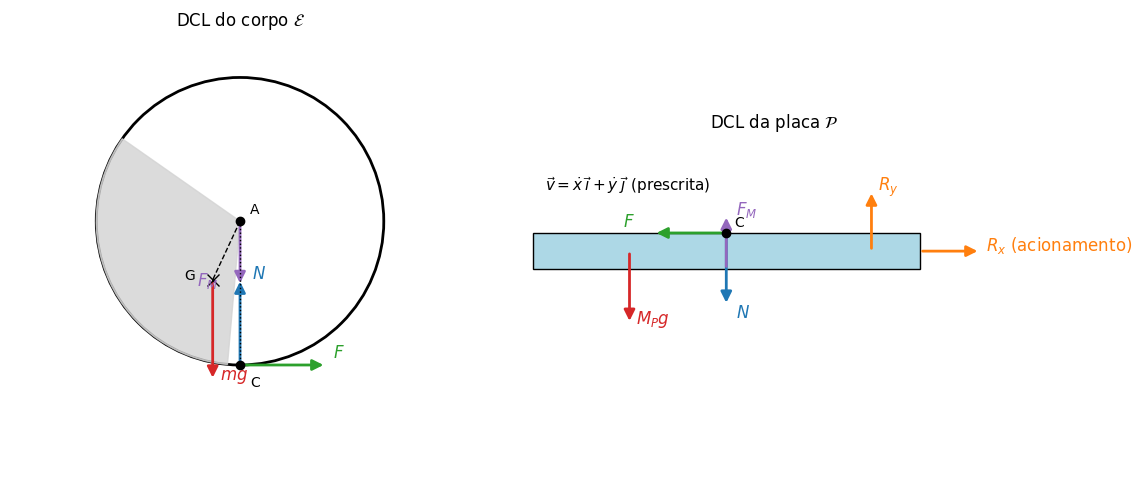

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
R_, e_, th_ = 1.0, 0.45, np.deg2rad(25)
A = np.array([0.0, R_]); G = A + e_*np.array([-np.sin(th_), -np.cos(th_)]); C = np.array([0.0, 0.0])

def seta(ax, p0, dvec, cor, rotulo, dx=0.05, dy=0.0):
    ax.add_patch(FancyArrowPatch(p0, p0 + dvec, arrowstyle="-|>", mutation_scale=16, color=cor, lw=2))
    ax.text(*(p0 + dvec + np.array([dx, dy])), rotulo, color=cor, fontsize=12)

# ---- corpo E
ax = axs[0]
ax.add_patch(Circle(A, R_, fill=False, lw=2))
ax.add_patch(Wedge(A, R_, 180 + np.rad2deg(th_) - 60, 180 + np.rad2deg(th_) + 60, color="lightgray", alpha=0.8))
ax.plot(*A, "ko"); ax.plot(*G, "kx", ms=8); ax.plot(*C, "ko")
ax.text(A[0] + 0.07, A[1] + 0.05, "A"); ax.text(G[0] - 0.2, G[1], "G"); ax.text(C[0] + 0.07, C[1] - 0.15, "C")
ax.plot([A[0], G[0]], [A[1], G[1]], "k--", lw=1); ax.plot([A[0], A[0]], [A[1], 0], "k:", lw=1)
seta(ax, G, np.array([0, -0.7]), "C3", "$mg$")
seta(ax, A, np.array([0, -0.45]), "C4", "$F_M$", dx=-0.3)
seta(ax, C, np.array([0, 0.6]), "C0", "$N$", dx=0.08)
seta(ax, C, np.array([0.6, 0]), "C2", "$F$", dy=0.05)
ax.set_title("DCL do corpo $\\mathcal{E}$"); ax.set_aspect("equal"); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-0.8, 2.3); ax.axis("off")

# ---- placa P
ax = axs[1]
ax.add_patch(Rectangle((-1.6, -0.3), 3.2, 0.3, color="lightblue", ec="k"))
ax.plot(0, 0, "ko"); ax.text(0.07, 0.05, "C")
seta(ax, np.array([0, 0]), np.array([0, -0.6]), "C0", "$N$", dx=0.08, dy=-0.1)
seta(ax, np.array([0, 0]), np.array([-0.6, 0]), "C2", "$F$", dx=-0.25, dy=0.05)
seta(ax, np.array([0.0, -0.3]), np.array([0, 0.45]), "C4", "$F_M$", dx=0.08)
seta(ax, np.array([-0.8, -0.15]), np.array([0, -0.6]), "C3", "$M_Pg$")
seta(ax, np.array([1.2, -0.15]), np.array([0, 0.5]), "C1", "$R_y$")
seta(ax, np.array([1.6, -0.15]), np.array([0.5, 0]), "C1", "$R_x$ (acionamento)")
ax.text(-1.5, 0.35, r"$\vec v=\dot x\,\vec\imath+\dot y\,\vec\jmath$ (prescrita)", fontsize=11)
ax.set_title("DCL da placa $\\mathcal{P}$"); ax.set_aspect("equal"); ax.set_xlim(-1.8, 2.6); ax.set_ylim(-1.2, 0.8); ax.axis("off")
plt.tight_layout(); plt.show()

## 2.2 Equação de movimento (TMQM com pólo em $A$ + TR horizontal)

### Cinemática

O ponto de contato $C$ do corpo tem a velocidade da placa (rolamento sem escorregamento sobre superfície móvel): $\vec v_C=\dot x_P\vec\imath+\dot y_P\vec\jmath$.
Com $\vec\omega=-\dot\theta\vec k$,

$$\vec v_A=\vec v_C+\vec\omega\times(A-C)=(\dot x_P+R\dot\theta)\vec\imath+\dot y_P\vec\jmath
\quad\Rightarrow\quad x_A=x_P+R\theta,\qquad y_A=y_P+R,$$

$$G-A=-e\sin\theta\,\vec\imath-e\cos\theta\,\vec\jmath\quad\Rightarrow\quad
\ddot x_G=\ddot x_P+(R-e\cos\theta)\ddot\theta+e\dot\theta^2\sin\theta,\qquad
\ddot y_G=\ddot y_P+e\ddot\theta\sin\theta+e\dot\theta^2\cos\theta .$$

### TMQM com pólo em $A$

O ponto $A$ é **acelerado** (não é fixo nem é o centro de massa), portanto deve-se usar a forma geral do teorema para um pólo móvel $O$,

$$\sum\vec M_O=I_G\,\vec\alpha+(G-O)\times m\,\vec a_G ,$$

(equivalente a $\sum\vec M_O=\dot{\vec H}_O+\vec v_O\times m\vec v_G$). O momento das forças externas em relação a $A$ é

$$\sum M_{A,z}=\big[(G-A)\times(-mg\vec\jmath)\big]_z+\big[(C-A)\times(F\vec\imath+N\vec\jmath)\big]_z=mge\sin\theta+RF ,$$

já que $F_M$ passa por $A$. O **TR na direção horizontal** fornece $F=m\ddot x_G$, o que elimina a incógnita de atrito. (O TR vertical,
$N=mg+F_M+m\ddot y_G$, só é necessário para verificar a condição de contato.)

In [3]:
t = sp.symbols("t")
m, R, e, g = sp.symbols("m R e g", positive=True)
th = sp.Function("theta")(t); thd, thdd = th.diff(t), th.diff(t, 2)
xP, yP = sp.Function("x_P")(t), sp.Function("y_P")(t)
F, N, FM = sp.symbols("F N F_M")
I_G = m*(R**2/2 - e**2)

# cinemática
xA, yA = xP + R*th, yP + R
rGA = sp.Matrix([-e*sp.sin(th), -e*sp.cos(th)])
xG, yG = xA + rGA[0], yA + rGA[1]
aG = sp.Matrix([xG.diff(t, 2), yG.diff(t, 2)])

# momento das forças externas em relação a A
rCA = sp.Matrix([0, -R])
M_A = (rGA[0]*(-m*g) - rGA[1]*0) + (rCA[0]*N - rCA[1]*F)
# lado dinâmico: I_G*alpha_z + [(G-A) x m a_G]_z   (alpha_z = -thdd)
H_A = I_G*(-thdd) + m*(rGA[0]*aG[1] - rGA[1]*aG[0])
TMQM_A = sp.Eq(M_A, H_A)

# TR horizontal
TR_x = sp.Eq(m*aG[0], F)
eom = sp.expand((TMQM_A.lhs - TMQM_A.rhs).subs(F, sp.solve(TR_x, F)[0]))
eom = sp.collect(sp.simplify(2*eom/m), [thdd, thd**2, xP.diff(t, 2), yP.diff(t, 2)])
print("Equação de movimento (x 2/m):"); display(sp.Eq(eom, 0))

# normal (TR vertical) para verificação de contato
N_expr = sp.solve(sp.Eq(m*aG[1], N - m*g - FM), N)[0]
print("N ="); display(sp.simplify(N_expr))

Equação de movimento (x 2/m):


                          2                                    2               ↪
                ⎛d       ⎞                                    d                ↪
2⋅R⋅e⋅sin(θ(t))⋅⎜──(θ(t))⎟  + 2⋅e⋅g⋅sin(θ(t)) + 2⋅e⋅sin(θ(t))⋅───(y_P(t)) + (2 ↪
                ⎝dt      ⎠                                      2              ↪
                                                              dt               ↪

↪                      2                                      2           
↪                     d             ⎛   2                  ⎞ d            
↪ ⋅R - 2⋅e⋅cos(θ(t)))⋅───(x_P(t)) + ⎝3⋅R  - 4⋅R⋅e⋅cos(θ(t))⎠⋅───(θ(t)) = 0
↪                       2                                      2          
↪                     dt                                     dt           

N =


                     2                                  2            2         
                    d                         ⎛d       ⎞            d          
F_M + e⋅m⋅sin(θ(t))⋅───(θ(t)) + e⋅m⋅cos(θ(t))⋅⎜──(θ(t))⎟  + g⋅m + m⋅───(y_P(t))
                      2                       ⎝dt      ⎠              2        
                    dt                                              dt         

Resultado:

$$\boxed{\;(3R^2-4Re\cos\theta)\,\ddot\theta+2Re\,\dot\theta^2\sin\theta+2e\,(g+\ddot y_P)\sin\theta+2(R-e\cos\theta)\,\ddot x_P=0\;}$$

Em relação à Parte 1 surgem dois termos novos, ambos de origem inercial:

* $2e\,\ddot y_P\sin\theta$ — a aceleração vertical da placa soma-se a $g$: tudo se passa como se a **gravidade efetiva** fosse $g_{ef}(t)=g+\ddot y_P(t)$;
* $2(R-e\cos\theta)\,\ddot x_P$ — a aceleração horizontal da placa atua como uma **força de inércia** $-m\ddot x_P$ aplicada em $G$, cujo braço em relação
  ao ponto de contato é $(R-e\cos\theta)$; esse termo não se anula em $\theta=0$, ou seja, é uma **excitação externa direta**.

### Verificação por Lagrange (vínculo reônomo)

O vínculo de rolamento sobre a placa móvel é holônomo e dependente do tempo ($x_A=x_P(t)+R\theta$), as reações de contato são ideais
(o ponto de contato não escorrega) e $F_M$ não realiza trabalho virtual (em $\delta\theta$ a $t$ fixo, $A$ se desloca horizontalmente).
Logo a equação de Lagrange com $L=T-V$ deve coincidir com a obtida pelos teoremas.

In [4]:
T_cin = sp.Rational(1, 2)*m*(xG.diff(t)**2 + yG.diff(t)**2) + sp.Rational(1, 2)*I_G*thd**2
V_pot = m*g*yG
L = T_cin - V_pot
eom_L = sp.collect(sp.expand(sp.simplify(2*(L.diff(thd).diff(t) - L.diff(th))/m)), [thdd, thd**2, xP.diff(t, 2), yP.diff(t, 2)])
display(sp.Eq(eom_L, 0))
print("Diferença (Lagrange - teoremas):", sp.simplify(eom_L - eom))

                          2                                    2               ↪
                ⎛d       ⎞                                    d                ↪
2⋅R⋅e⋅sin(θ(t))⋅⎜──(θ(t))⎟  + 2⋅e⋅g⋅sin(θ(t)) + 2⋅e⋅sin(θ(t))⋅───(y_P(t)) + (2 ↪
                ⎝dt      ⎠                                      2              ↪
                                                              dt               ↪

↪                      2                                      2           
↪                     d             ⎛   2                  ⎞ d            
↪ ⋅R - 2⋅e⋅cos(θ(t)))⋅───(x_P(t)) + ⎝3⋅R  - 4⋅R⋅e⋅cos(θ(t))⎠⋅───(θ(t)) = 0
↪                       2                                      2          
↪                     dt                                     dt           

Diferença (Lagrange - teoremas): 0


In [5]:
# substitui o movimento prescrito da placa e isola theta''
Ax, Ay, wx, wy, phx, phy = sp.symbols("A_x A_y omega_x omega_y phi_x phi_y", real=True)
xP_t = -Ax*sp.cos(wx*t + phx)       # tal que x_P' = A_x w_x sin(w_x t + phi_x)
yP_t = -Ay*sp.cos(wy*t + phy)
print("Verificação das velocidades prescritas:", sp.simplify(xP_t.diff(t)), ",", sp.simplify(yP_t.diff(t)))
eom_t = eom.subs({xP: xP_t, yP: yP_t}).doit()
thdd_expr = sp.simplify(sp.solve(sp.Eq(eom_t, 0), thdd)[0])
print("theta'' ="); display(thdd_expr)

Verificação das velocidades prescritas: A_x*omega_x*sin(omega_x*t + phi_x) , A_y*omega_y*sin(omega_y*t + phi_y)


theta'' =


  ⎛                                                                            ↪
  ⎜       2                         2                                     2    ↪
2⋅⎜Aₓ⋅R⋅ωₓ ⋅cos(ωₓ⋅t + φₓ) - Aₓ⋅e⋅ωₓ ⋅cos(ωₓ⋅t + φₓ)⋅cos(θ(t)) + A_y⋅e⋅ω_y ⋅si ↪
  ⎝                                                                            ↪
────────────────────────────────────────────────────────────────────────────── ↪
                                                             R⋅(-3⋅R + 4⋅e⋅cos ↪

↪                                                    2                ⎞
↪                                          ⎛d       ⎞                 ⎟
↪ n(θ(t))⋅cos(ω_y⋅t + φ_y) + R⋅e⋅sin(θ(t))⋅⎜──(θ(t))⎟  + e⋅g⋅sin(θ(t))⎟
↪                                          ⎝dt      ⎠                 ⎠
↪ ─────────────────────────────────────────────────────────────────────
↪ (θ(t)))                                                              

## 2.3 Linearização em torno de $\theta=0$ e frequência natural

Sem excitação ($\ddot x_P=\ddot y_P=0$) a configuração $\theta=0$ é o equilíbrio estável (Parte 1). Linearizando a equação em torno de
$\theta=0,\ \dot\theta=0$ (mantendo os termos de excitação, que são de ordem zero ou um em $\theta$):

$$R(3R-4e)\,\ddot\theta+2e\,(g+\ddot y_P)\,\theta=-2(R-e)\,\ddot x_P
\qquad\Longleftrightarrow\qquad
\ddot\theta+\omega_n^2\left(1+\frac{\ddot y_P}{g}\right)\theta=-\omega_n^2\left(\frac Re-1\right)\frac{\ddot x_P}{g},$$

com a **mesma frequência natural da Parte 1**:

$$\omega_n=\sqrt{\frac{2ge}{R(3R-4e)}} .$$

A frequência natural é a do sistema homogêneo não excitado; a excitação vertical a **modula no tempo** e a horizontal aparece como **forçamento**.

In [6]:
TH, W, A_ = sp.symbols("vartheta omega a")
f_sym = eom_t.subs({thdd: A_, thd: W, th: TH})
subs0 = {TH: 0, W: 0, A_: 0}
c2 = sp.simplify(f_sym.diff(A_).subs(subs0)); c1 = sp.simplify(f_sym.diff(W).subs(subs0))
c0 = sp.simplify(f_sym.diff(TH).subs(subs0)); cf = sp.simplify(f_sym.subs(subs0))     # termo independente (forçamento)
lin = sp.Eq(c2*thdd + c1*thd + c0*th, -cf)
print("Equação linearizada:"); display(lin)

omega_n = sp.sqrt(sp.simplify(c0.subs({Ay: 0})/c2))
print("omega_n ="); display(omega_n)
g_num, R_num = 9.8, 0.30; e_num = 0.20*R_num
wn_num = float(omega_n.subs({g: g_num, R: R_num, e: e_num}))
print(f"Valor numérico (e = 0,2R): omega_n = {wn_num:.4f} rad/s,  T_n = {2*np.pi/wn_num:.4f} s")

Equação linearizada:


               2                                                               ↪
              d               ⎛       2                     ⎞                2 ↪
R⋅(3⋅R - 4⋅e)⋅───(θ(t)) + 2⋅e⋅⎝A_y⋅ω_y ⋅cos(ω_y⋅t + φ_y) + g⎠⋅θ(t) = -2⋅Aₓ⋅ωₓ  ↪
                2                                                              ↪
              dt                                                               ↪

↪                        
↪                        
↪ ⋅(R - e)⋅cos(ωₓ⋅t + φₓ)
↪                        
↪                        

omega_n =


             ___________
            ╱     1     
√2⋅√e⋅√g⋅  ╱  ───────── 
         ╲╱   3⋅R - 4⋅e 
────────────────────────
           √R           

Valor numérico (e = 0,2R): omega_n = 2.4371 rad/s,  T_n = 2.5782 s


## 2.4 Ressonância paramétrica e a equação de Mathieu

### Breve pesquisa

Diz-se que um sistema está sujeito a **excitação paramétrica** quando um de seus *parâmetros* (rigidez, inércia, comprimento, gravidade efetiva…)
varia no tempo, em vez de haver uma força externa aplicada. O protótipo é a **equação de Mathieu** (1868, vibrações de membranas elípticas),

$$\ddot\theta+\omega_n^2\big(1+\epsilon\cos\Omega t\big)\theta=0 ,$$

que, apesar de linear, tem coeficientes periódicos: pela **teoria de Floquet** as soluções são da forma $e^{\mu t}p(t)$ com $p$ periódica,
e a estabilidade depende do par $(\Omega/\omega_n,\epsilon)$ segundo o **diagrama de Ince–Strutt**: existem "línguas" de instabilidade que nascem,
para $\epsilon\to0$, em

$$\Omega=\frac{2\omega_n}{n},\qquad n=1,2,3,\dots$$

A mais larga (e que se abre mais rápido com $\epsilon$) é a **ressonância paramétrica principal** $\Omega=2\omega_n$: o parâmetro oscila com o dobro da frequência
natural, como a criança que se levanta e abaixa duas vezes por ciclo no balanço, ou o pêndulo de comprimento variável. Diferenças em relação à ressonância
comum (forçada):

| | ressonância fundamental (forçada) | ressonância paramétrica |
|---|---|---|
| origem | força externa $\propto\cos\omega_xt$ | variação periódica de um parâmetro |
| condição | $\omega_x=\omega_n$ | $\Omega\approx2\omega_n/n$ (faixas de largura $\sim\epsilon$) |
| $\theta\equiv0$ é solução? | não | **sim** — a instabilidade só se manifesta a partir de uma perturbação |
| crescimento linear | **linear** no tempo ($\theta\sim t\sin\omega_nt$) | **exponencial** ($\theta\sim e^{\mu t}$) |
| efeito do amortecimento | limita a amplitude | cria um **limiar** em $\epsilon$ abaixo do qual não há instabilidade |

Exemplos clássicos: o pêndulo de Kapitza (pêndulo invertido estabilizado por vibração vertical rápida do pivô — o lado "estabilizador" da mesma equação),
o *roll* paramétrico de navios porta-contêineres em mar de proa (a variação da área de linha d'água altera o $GM$ com a frequência de encontro das ondas
$\approx2\omega_{roll}$), e a instabilidade de colunas sob carga axial pulsante.

### Comparação com a equação linearizada obtida

A equação do item 2.3 é exatamente uma **equação de Mathieu forçada**:

$$\ddot\theta+\omega_n^2\big(1+\epsilon_y\cos(\omega_yt+\phi_y)\big)\theta=-\omega_n^2\epsilon_x\cos(\omega_xt+\phi_x),$$

com

$$\epsilon_x=\left(\frac Re-1\right)\frac{A_x\omega_x^2}{g},\qquad \epsilon_y=\frac{A_y\omega_y^2}{g},$$

como se verifica abaixo com `sympy`. Interpretação:

* o termo em $\cos(\omega_yt+\phi_y)$ multiplica $\theta$: a aceleração vertical da placa modula a **gravidade efetiva** $g(1+\epsilon_y\cos\omega_yt)$,
  isto é, a *rigidez* do "pêndulo" — **excitação paramétrica**; $\epsilon_y$ é a razão entre a amplitude da aceleração vertical e $g$;
* o termo em $\cos(\omega_xt+\phi_x)$ é independente de $\theta$: a aceleração horizontal gera uma força de inércia que **força** diretamente o movimento —
  **excitação externa**, com ressonância fundamental em $\omega_x=\omega_n$; o fator $(R/e-1)$ é a razão entre o braço $(R-e)$ da força de inércia e o braço $e$
  do peso em relação ao contato.

In [7]:
# divide a equação linearizada pelo coeficiente de theta'' e compara com a forma de Mathieu forçada
eps_x, eps_y = sp.symbols("epsilon_x epsilon_y")
lhs = sp.expand((c2*thdd + c0*th)/c2); rhs = sp.expand(-cf/c2)
coef_theta = sp.simplify(sp.expand(lhs.coeff(th)/omega_n**2))               # deve ser 1 + eps_y cos(...)
eps_y_sol = sp.simplify((coef_theta - 1)/sp.cos(wy*t + phy))
eps_x_sol = sp.simplify(-rhs/(omega_n**2*sp.cos(wx*t + phx)))
print("Coeficiente de theta dividido por omega_n^2:"); display(coef_theta)
print("epsilon_y ="); display(eps_y_sol)
print("epsilon_x ="); display(sp.factor(eps_x_sol))
print("Confere com (R/e - 1) A_x w_x^2 / g ?", sp.simplify(eps_x_sol - (R/e - 1)*Ax*wx**2/g) == 0)
print("Confere com A_y w_y^2 / g ?", sp.simplify(eps_y_sol - Ay*wy**2/g) == 0)

Coeficiente de theta dividido por omega_n^2:


       2                     
A_y⋅ω_y ⋅cos(ω_y⋅t + φ_y) + g
─────────────────────────────
              g              

epsilon_y =


       2
A_y⋅ω_y 
────────
   g    

epsilon_x =


      2          
-Aₓ⋅ωₓ ⋅(-R + e) 
─────────────────
       e⋅g       

Confere com (R/e - 1) A_x w_x^2 / g ? True
Confere com A_y w_y^2 / g ? True


### Diagrama de estabilidade (Ince–Strutt) para a parte paramétrica

Para situar os cenários do item 2.7, calcula-se numericamente a estabilidade da equação homogênea
$\ddot\theta+\omega_n^2(1+\epsilon_y\cos\omega_yt)\theta=0$ pelo método de Floquet: integra-se a matriz fundamental ao longo de um período
$T=2\pi/\omega_y$ (matriz de monodromia $\Phi$) e o movimento é instável se o maior multiplicador $|\mu|=\max|\mathrm{eig}\,\Phi|$ excede 1
(taxa de crescimento $\sigma=\ln|\mu|/T$). Como $A_y=1{,}25R$ é fixo nos cenários, $\epsilon_y=(A_y\omega_n^2/g)(\omega_y/\omega_n)^2$ descreve uma
parábola no plano $(\omega_y/\omega_n,\epsilon_y)$, marcada no diagrama.

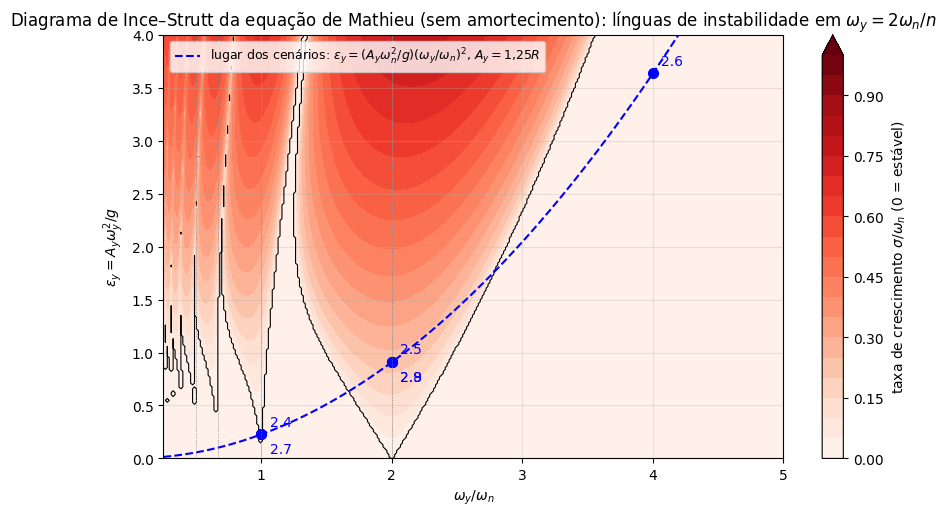

Multiplicador de Floquet e taxa de crescimento prevista pela teoria linear nos cenários com excitação vertical:
  cenário 2.4: omega_y/omega_n = 1.0, eps_y = 0.227, |mu|max = 1.0307, sigma = 0.0117 1/s (INSTÁVEL)
  cenário 2.5: omega_y/omega_n = 2.0, eps_y = 0.909, |mu|max = 2.0090, sigma = 0.5412 1/s (INSTÁVEL)
  cenário 2.6: omega_y/omega_n = 4.0, eps_y = 3.636, |mu|max = 1.0000, sigma = 0.0000 1/s (estável)


In [8]:
def floquet_mathieu(ratio, eps, n_steps=600):
    # Maior multiplicador de Floquet de  theta'' + (1 + eps cos(ratio*tau)) theta = 0  (tau = omega_n t),
    # integrando a matriz fundamental ao longo de um período 2pi/ratio com RK4 vetorizado em toda a grade.
    ratio = np.asarray(ratio, float); eps = np.asarray(eps, float)
    T = 2*np.pi/ratio; h = T/n_steps
    X = np.zeros((4,) + ratio.shape); X[0] = 1.0; X[3] = 1.0          # colunas [x1, v1], [x2, v2]
    def f(tau, X):
        c = 1.0 + eps*np.cos(ratio*tau)
        return np.array([X[1], -c*X[0], X[3], -c*X[2]])
    tau = np.zeros_like(ratio)
    for _ in range(n_steps):
        k1 = f(tau, X); k2 = f(tau + h/2, X + h/2*k1); k3 = f(tau + h/2, X + h/2*k2); k4 = f(tau + h, X + h*k3)
        X = X + h/6*(k1 + 2*k2 + 2*k3 + k4); tau = tau + h
    tr = X[0] + X[3]                                                   # det(Phi) = 1 (Liouville)
    disc = tr**2 - 4.0
    mu_max = np.where(disc > 0, (np.abs(tr) + np.sqrt(np.abs(disc)))/2, 1.0)
    return mu_max, T

ratios = np.linspace(0.25, 5.0, 320); epss = np.linspace(0.0, 4.0, 220)
RG, EG = np.meshgrid(ratios, epss)
mu, Tper = floquet_mathieu(RG, EG)
sigma = np.log(np.maximum(mu, 1.0))/Tper            # taxa de crescimento adimensional (por unidade de omega_n t)

A_num = 1.25*R_num
fig, ax = plt.subplots(figsize=(10, 5.5))
cf_ = ax.contourf(RG, EG, sigma, levels=np.linspace(0, 1.0, 21), cmap="Reds", extend="max")
plt.colorbar(cf_, label=r"taxa de crescimento $\sigma/\omega_n$ (0 = estável)")
ax.contour(RG, EG, mu, levels=[1.0001], colors="k", linewidths=0.8)
par = (A_num*wn_num**2/g_num)*ratios**2
ax.plot(ratios, par, "b--", lw=1.5, label=r"lugar dos cenários: $\epsilon_y=(A_y\omega_n^2/g)(\omega_y/\omega_n)^2$, $A_y=1{,}25R$")
for nome, rr in {"2.4": 1.0, "2.5": 2.0, "2.6": 4.0, "2.7": 1.0, "2.8": 2.0, "2.9": 2.0}.items():
    ev = (A_num*wn_num**2/g_num)*rr**2
    ax.plot(rr, ev, "bo", ms=7); ax.annotate(nome, (rr, ev), xytext=(6, 6 if nome in ("2.4", "2.5", "2.6") else -14), textcoords="offset points", color="b")
for n in [1, 2, 3, 4]:
    ax.axvline(2/n, color="gray", lw=0.6, ls=":")
ax.set_xlabel(r"$\omega_y/\omega_n$"); ax.set_ylabel(r"$\epsilon_y = A_y\omega_y^2/g$"); ax.set_ylim(0, 4)
ax.set_title("Diagrama de Ince–Strutt da equação de Mathieu (sem amortecimento): línguas de instabilidade em $\\omega_y=2\\omega_n/n$")
ax.legend(loc="upper left", fontsize=9); plt.show()

print("Multiplicador de Floquet e taxa de crescimento prevista pela teoria linear nos cenários com excitação vertical:")
for nome, rr in {"2.4": 1.0, "2.5": 2.0, "2.6": 4.0}.items():
    ev = (A_num*wn_num**2/g_num)*rr**2
    mu1, T1 = floquet_mathieu(np.array([rr]), np.array([ev]))
    s = np.log(max(mu1[0], 1))/T1[0]*wn_num
    print(f"  cenário {nome}: omega_y/omega_n = {rr:.1f}, eps_y = {ev:.3f}, |mu|max = {mu1[0]:.4f}, sigma = {s:.4f} 1/s "
          + ("(INSTÁVEL)" if mu1[0] > 1.0001 else "(estável)"))

## 2.5 Forma de espaço de estados

Com $\mathbf y=[\theta,\ \dot\theta]^T$ e as acelerações prescritas $\ddot x_P(t)=A_x\omega_x^2\cos(\omega_xt+\phi_x)$,
$\ddot y_P(t)=A_y\omega_y^2\cos(\omega_yt+\phi_y)$:

$$\dot y_1=y_2,\qquad
\dot y_2=-\frac{2Re\,y_2^2\sin y_1+2e\,\big(g+\ddot y_P(t)\big)\sin y_1+2\big(R-e\cos y_1\big)\ddot x_P(t)}{3R^2-4Re\cos y_1}.$$

Diferentemente da Parte 1, o sistema é **não-autônomo** ($\mathbf f$ depende explicitamente de $t$) e não conserva energia: a placa realiza trabalho sobre o corpo.

In [9]:
y1, y2 = sp.symbols("y1 y2")
f_estado = sp.Matrix([y2, thdd_expr.subs({thd: y2, th: y1})])
print("f(t, y) ="); display(f_estado)

f(t, y) =


⎡                                                                y₂            ↪
⎢                                                                              ↪
⎢  ⎛       2                         2                                   2     ↪
⎢2⋅⎝Aₓ⋅R⋅ωₓ ⋅cos(ωₓ⋅t + φₓ) - Aₓ⋅e⋅ωₓ ⋅cos(y₁)⋅cos(ωₓ⋅t + φₓ) + A_y⋅e⋅ω_y ⋅sin ↪
⎢───────────────────────────────────────────────────────────────────────────── ↪
⎣                                                      R⋅(-3⋅R + 4⋅e⋅cos(y₁))  ↪

↪                                                       ⎤
↪                                                       ⎥
↪                               2                      ⎞⎥
↪ (y₁)⋅cos(ω_y⋅t + φ_y) + R⋅e⋅y₂ ⋅sin(y₁) + e⋅g⋅sin(y₁)⎠⎥
↪ ──────────────────────────────────────────────────────⎥
↪                                                       ⎦

## 2.6 Rotina de integração numérica

Versão Python com `solve_ivp` (Dormand–Prince 8(5,3), tolerâncias apertadas, passo máximo limitado a uma fração do menor período envolvido).
Equivalente Scilab com a função `ode`:

```scilab
// EMSC 2019 - Parte 2 : corpo sobre placa em translação prescrita
g = 9.8; R = 0.30; e = 0.20*R;
wn = sqrt(2*g*e/(R*(3*R-4*e)));
Ax = 1.25*R; wx = 1.0*wn; phx = 0;  Ay = 0; wy = 0; phy = 0;   // cenário 2.2

function dy = f(t, y)
    th = y(1); om = y(2);
    xPdd = Ax*wx^2*cos(wx*t + phx);
    yPdd = Ay*wy^2*cos(wy*t + phy);
    dy(1) = om;
    dy(2) = -(2*R*e*om^2*sin(th) + 2*e*(g + yPdd)*sin(th) + 2*(R - e*cos(th))*xPdd) / (3*R^2 - 4*R*e*cos(th));
endfunction

t  = 0:0.01:120;
y0 = [%pi/6; 0];
y  = ode(y0, 0, t, f);
subplot(3,1,1); plot(t, y(1,:)); subplot(3,1,2); plot(t, y(2,:)); subplot(3,1,3); plot(y(1,:), y(2,:));
```

In [10]:
def f_estados(t, y, p):
    th_, om_ = y
    xPdd = p["Ax"]*p["wx"]**2*np.cos(p["wx"]*t + p["phx"])
    yPdd = p["Ay"]*p["wy"]**2*np.cos(p["wy"]*t + p["phy"])
    R_, e_, g_ = p["R"], p["e"], p["g"]
    return [om_, -(2*R_*e_*om_**2*np.sin(th_) + 2*e_*(g_ + yPdd)*np.sin(th_) + 2*(R_ - e_*np.cos(th_))*xPdd) / (3*R_**2 - 4*R_*e_*np.cos(th_))]

def simular(p, theta0=np.pi/6, omega0=0.0, t_final=120.0, dt=0.01):
    t_eval = np.arange(0.0, t_final + dt/2, dt)
    w_max = max(p["wx"], p["wy"], np.sqrt(2*p["g"]*p["e"]/(p["R"]*(3*p["R"] - 4*p["e"]))))
    sol = solve_ivp(f_estados, (0.0, t_final), [theta0, omega0], t_eval=t_eval, args=(p,),
                    method="DOP853", rtol=1e-10, atol=1e-12, max_step=0.05*2*np.pi/w_max)
    return sol.t, sol.y[0], sol.y[1]

def parametros(Ax=0.0, wx=0.0, phx=0.0, Ay=0.0, wy=0.0, phy=0.0, R=0.30, e=0.06, g=9.8):
    return dict(Ax=Ax, wx=wx, phx=phx, Ay=Ay, wy=wy, phy=phy, R=R, e=e, g=g)

# teste: sem excitação deve reproduzir a Parte 1 (energia conservada)
tt, th_t, om_t = simular(parametros(), t_final=20.0)
E = 0.5*(1.5*R_num**2 - 2*R_num*e_num*np.cos(th_t))*om_t**2 + g_num*(R_num - e_num*np.cos(th_t))
print(f"Sem excitação: variação relativa máxima da energia = {np.max(np.abs(E - E[0]))/E[0]:.2e}")

Sem excitação: variação relativa máxima da energia = 7.14e-12


## 2.7 Simulação dos cenários propostos

Parâmetros: $g=9{,}8$ m/s², $R=0{,}30$ m, $e=0{,}2R$, $\theta(0)=\pi/6$, $\dot\theta(0)=0$, simulação até $t=120$ s, $\omega_n=2{,}437$ rad/s.
Para cada cenário: (a) $\theta(t)$, (b) $\dot\theta(t)$, (c) espaço de fase. Nos cenários em que o corpo passa a dar voltas completas, $\theta$ cresce
sem limite e o retrato de fase "desenrola"; os gráficos mostram $\theta$ sem redução módulo $2\pi$.

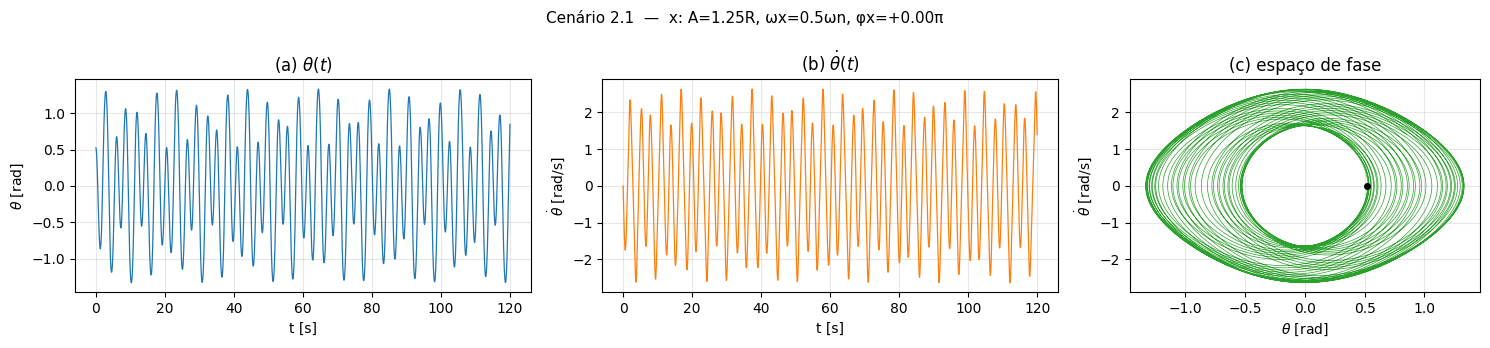

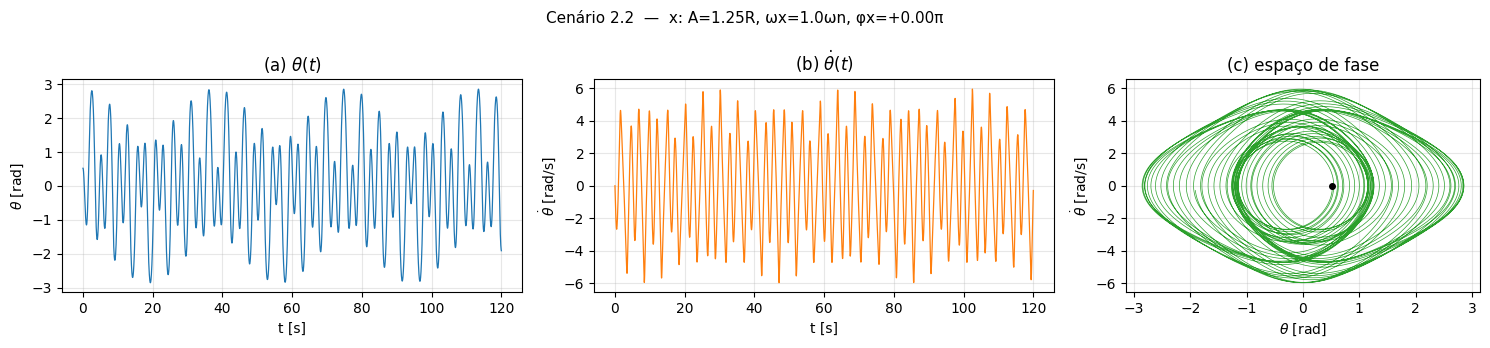

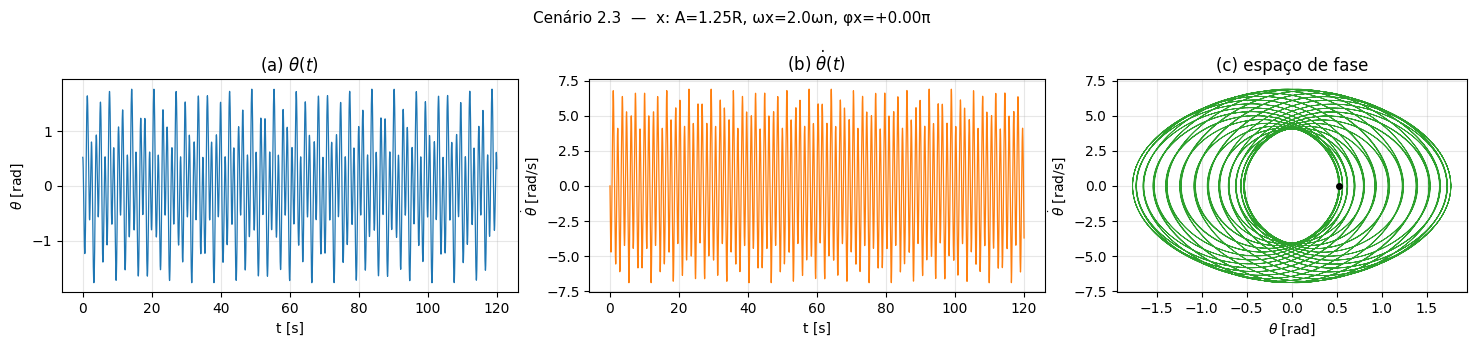

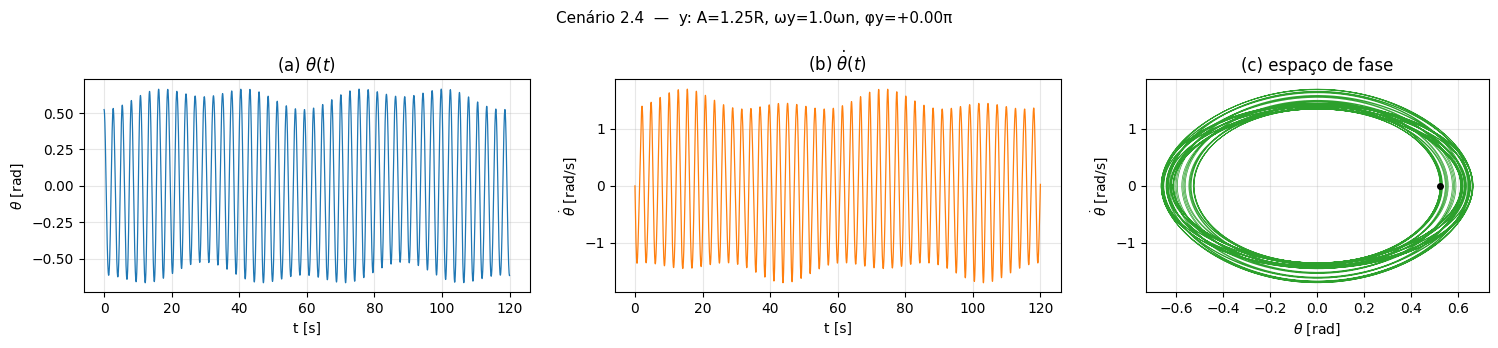

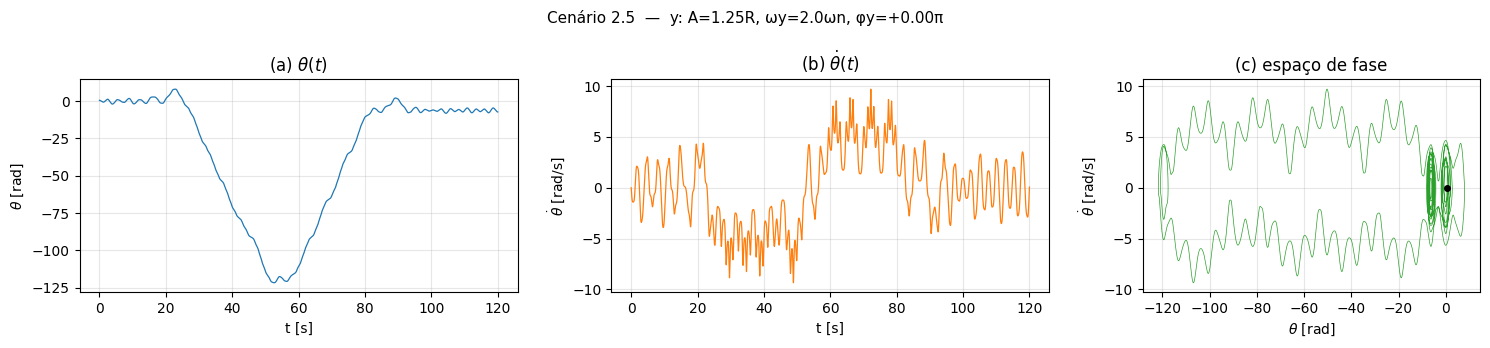

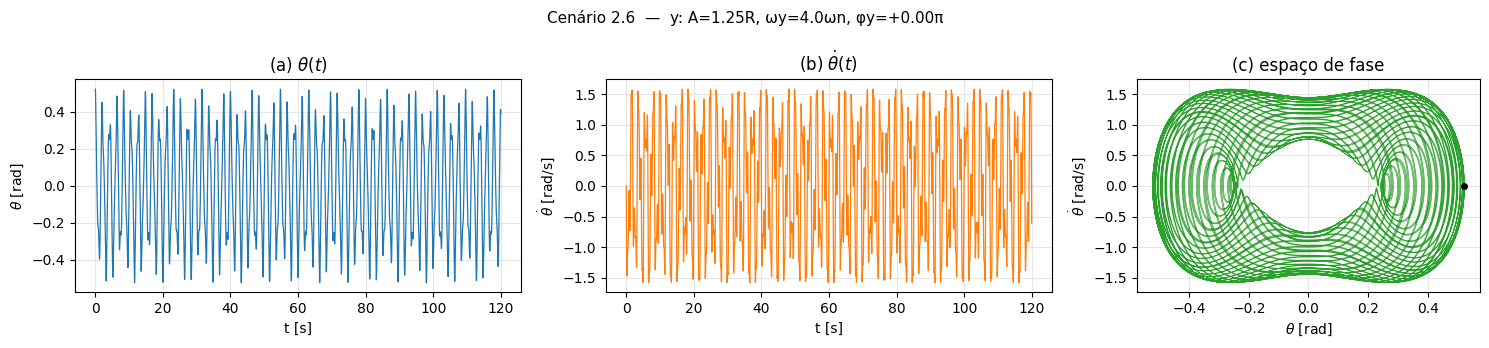

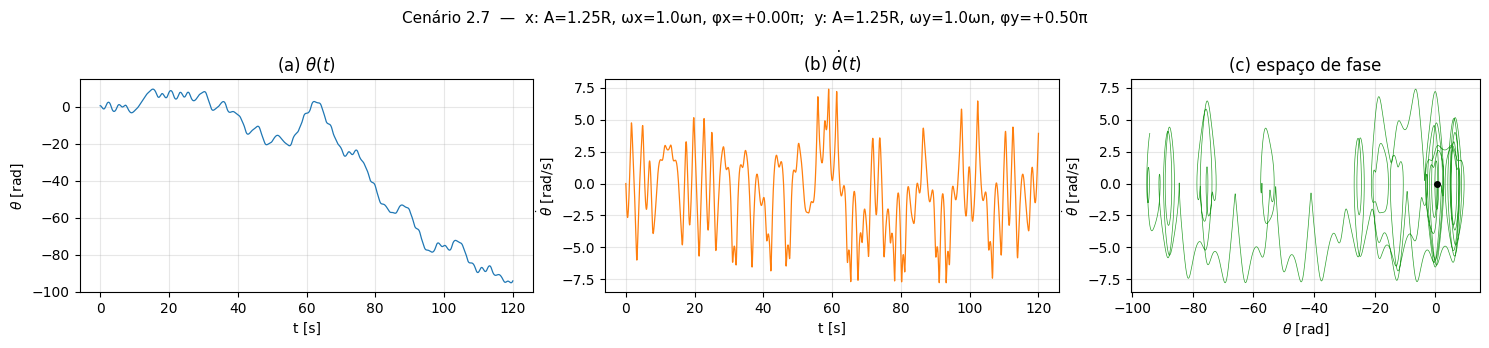

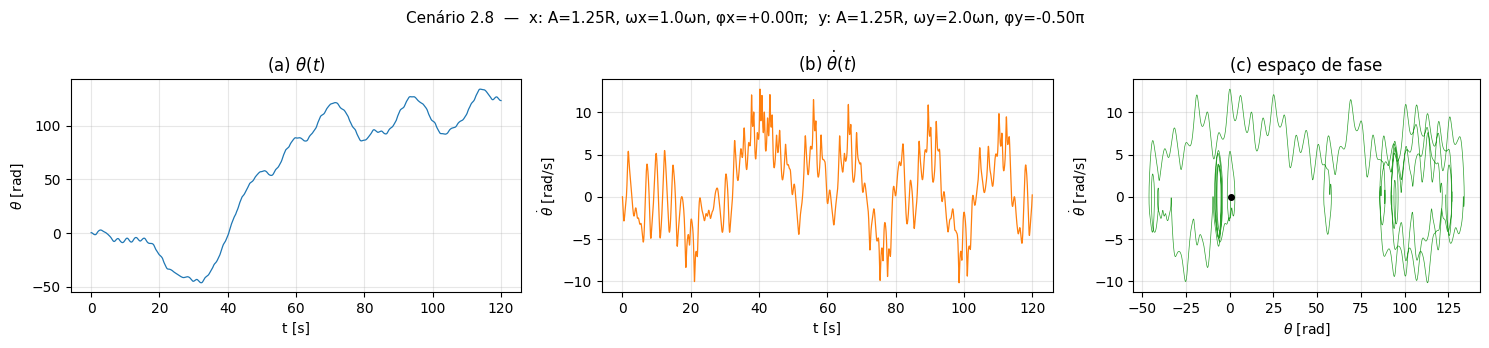

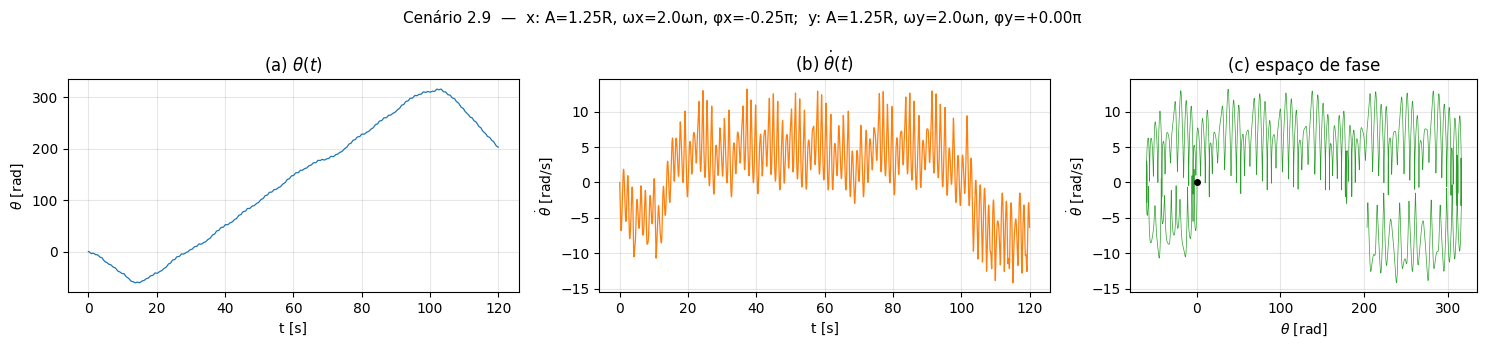

In [11]:
A_num = 1.25*R_num
cenarios = {
    "2.1": parametros(Ax=A_num, wx=0.5*wn_num),
    "2.2": parametros(Ax=A_num, wx=1.0*wn_num),
    "2.3": parametros(Ax=A_num, wx=2.0*wn_num),
    "2.4": parametros(Ay=A_num, wy=1.0*wn_num),
    "2.5": parametros(Ay=A_num, wy=2.0*wn_num),
    "2.6": parametros(Ay=A_num, wy=4.0*wn_num),
    "2.7": parametros(Ax=A_num, wx=1.0*wn_num, phx=0.0,      Ay=A_num, wy=1.0*wn_num, phy=np.pi/2),
    "2.8": parametros(Ax=A_num, wx=1.0*wn_num, phx=0.0,      Ay=A_num, wy=2.0*wn_num, phy=-np.pi/2),
    "2.9": parametros(Ax=A_num, wx=2.0*wn_num, phx=-np.pi/4, Ay=A_num, wy=2.0*wn_num, phy=0.0),
}

def descricao(p):
    s = []
    if p["Ax"] > 0: s.append(f"x: A={p['Ax']/R_num:.2f}R, ωx={p['wx']/wn_num:.1f}ωn, φx={p['phx']/np.pi:+.2f}π")
    if p["Ay"] > 0: s.append(f"y: A={p['Ay']/R_num:.2f}R, ωy={p['wy']/wn_num:.1f}ωn, φy={p['phy']/np.pi:+.2f}π")
    return ";  ".join(s)

resultados = {}
for nome, p in cenarios.items():
    t_, th_, om_ = simular(p)
    resultados[nome] = (t_, th_, om_)
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.5), gridspec_kw={"width_ratios": [1.3, 1.3, 1]})
    fig.suptitle(f"Cenário {nome}  —  {descricao(p)}", fontsize=11)
    axs[0].plot(t_, th_, lw=0.9); axs[0].set_xlabel("t [s]"); axs[0].set_ylabel(r"$\theta$ [rad]"); axs[0].set_title(r"(a) $\theta(t)$")
    axs[1].plot(t_, om_, lw=0.9, color="C1"); axs[1].set_xlabel("t [s]"); axs[1].set_ylabel(r"$\dot\theta$ [rad/s]"); axs[1].set_title(r"(b) $\dot\theta(t)$")
    axs[2].plot(th_, om_, lw=0.5, color="C2"); axs[2].plot(th_[0], om_[0], "ko", ms=4)
    axs[2].set_xlabel(r"$\theta$ [rad]"); axs[2].set_ylabel(r"$\dot\theta$ [rad/s]"); axs[2].set_title("(c) espaço de fase")
    plt.tight_layout(); plt.show()

## 2.8 Interpretação física: ressonância fundamental e ressonância paramétrica

A tabela abaixo reúne, para cada cenário, os parâmetros adimensionais da equação de Mathieu forçada ($\epsilon_x$, $\epsilon_y$), a previsão linear
(amplitude forçada $\epsilon_x/|1-(\omega_x/\omega_n)^2|$ e multiplicador de Floquet da parte paramétrica) e as medidas da simulação não-linear
(amplitude máxima, amplitude no trecho final e ocorrência de voltas completas).

In [12]:
def resumo(nome, p, t_, th_, om_):
    rx = p["wx"]/wn_num if p["Ax"] > 0 else np.nan; ry = p["wy"]/wn_num if p["Ay"] > 0 else np.nan
    ex = (R_num/e_num - 1)*p["Ax"]*p["wx"]**2/g_num; ey = p["Ay"]*p["wy"]**2/g_num
    amp_lin = ex/abs(1 - rx**2) if p["Ax"] > 0 and abs(1 - rx**2) > 1e-9 else (np.inf if p["Ax"] > 0 else 0.0)
    if p["Ay"] > 0:
        mu1, _ = floquet_mathieu(np.array([ry]), np.array([ey])); mu1 = mu1[0]
    else:
        mu1 = 1.0
    voltas = np.max(np.abs(th_)) > np.pi
    fim = t_ > 100.0
    return dict(rx=rx, ry=ry, ex=ex, ey=ey, amp_lin=amp_lin, mu=mu1, max_th=np.max(np.abs(th_)),
                amp_fim=np.max(np.abs(th_[fim] - np.mean(th_[fim]))), voltas=voltas, max_om=np.max(np.abs(om_)))

print(" Cen.  ωx/ωn  ωy/ωn    εx      εy   |θ|lin forçada  |μ|Floquet   max|θ| [rad]  ampl. final  max|θ̇|  voltas completas?")
tabela = {}
for nome, p in cenarios.items():
    r = resumo(nome, p, *resultados[nome]); tabela[nome] = r
    print(f"  {nome}   {r['rx']:4.1f}   {r['ry']:4.1f}   {r['ex']:5.3f}  {r['ey']:5.3f}     {r['amp_lin']:7.3f}       {r['mu']:7.3f}      {r['max_th']:7.3f}      {r['amp_fim']:7.3f}    {r['max_om']:6.2f}      {'SIM' if r['voltas'] else 'não'}")

 Cen.  ωx/ωn  ωy/ωn    εx      εy   |θ|lin forçada  |μ|Floquet   max|θ| [rad]  ampl. final  max|θ̇|  voltas completas?
  2.1    0.5    nan   0.227  0.000       0.303         1.000        1.331        1.352      2.63      não
  2.2    1.0    nan   0.909  0.000         inf         1.000        2.859        2.685      5.97      não
  2.3    2.0    nan   3.636  0.000       1.212         1.000        1.771        1.780      6.89      não
  2.4    nan    1.0   0.000  0.227       0.000         1.031        0.665        0.707      1.70      não
  2.5    nan    2.0   0.000  0.909       0.000         2.009      121.673        1.874      9.70      SIM
  2.6    nan    4.0   0.000  3.636       0.000         1.000        0.524        0.524      1.58      não
  2.7    1.0    1.0   0.909  0.227         inf         1.031       95.202       12.485      7.76      SIM


  2.8    1.0    2.0   0.909  0.909         inf         2.009      134.060       21.261     12.73      SIM
  2.9    2.0    2.0   3.636  0.909       1.212         2.009      316.117       67.806     14.16      SIM


**Cenários com excitação horizontal (forçamento direto):**

* **2.1** ($\omega_x=0{,}5\omega_n$): resposta quase-periódica, superposição da oscilação livre em $\omega_n$ (iniciada por $\theta_0=\pi/6$) com a forçada
  em $\omega_x$, de amplitude moderada ($\epsilon_x/|1-r^2|\approx0{,}3$ rad); o retrato de fase é uma faixa limitada (toro). Não há ressonância.
* **2.2** ($\omega_x=\omega_n$, $\epsilon_x\approx0{,}91$): **ressonância fundamental**. Na teoria linear a amplitude cresceria linearmente sem limite
  ($\theta\sim t\sin\omega_nt$); no modelo não-linear o período de oscilação alonga com a amplitude (Parte 1), o sistema "sai de sintonia" e a energia é
  devolvida à placa — o crescimento é limitado e a resposta apresenta grandes **batimentos**, com $|\theta|$ chegando a quase $2{,}9$ rad (o corpo quase
  atinge a posição invertida) sem completar voltas. O retrato de fase preenche uma região anelar larga.
* **2.3** ($\omega_x=2\omega_n$, $\epsilon_x\approx3{,}6$): forçamento acima da ressonância. Como $\epsilon_x\propto\omega_x^2$, a força de inércia é grande e a
  amplitude forçada linear ($\epsilon_x/|r^2-1|\approx1{,}2$ rad) não é desprezível, mas a resposta é **limitada e em oposição de fase**; a oscilação livre
  em $\omega_n$ se superpõe, produzindo uma resposta quase-periódica de amplitude máxima $\approx1{,}8$ rad. Sem ressonância.

**Cenários com excitação vertical (paramétrica):**

* **2.4** ($\omega_y=\omega_n$, $\epsilon_y\approx0{,}23$): o ponto cai na **segunda língua** ($n=2$) do diagrama de Ince–Strutt, muito estreita para esse
  $\epsilon_y$: o multiplicador de Floquet é apenas ligeiramente maior que 1 (taxa de crescimento $\sim0{,}01$ s$^{-1}$). A resposta é a oscilação iniciada
  por $\theta_0=\pi/6$ com uma modulação lenta de amplitude (entre $0{,}5$ e $0{,}7$ rad), rapidamente saturada pela não-linearidade — ressonância paramétrica
  secundária, branda.
* **2.5** ($\omega_y=2\omega_n$, $\epsilon_y\approx0{,}91$): **ressonância paramétrica principal**. O multiplicador de Floquet é $\approx2$ por período
  (taxa de crescimento $\sim0{,}5$ s$^{-1}$): a amplitude cresce **exponencialmente** a partir de $\theta_0=\pi/6$ e em poucos segundos o corpo passa a dar
  **voltas completas** ($\theta$ chega a $\approx-120$ rad, cerca de 19 voltas, alternando trechos de rotação e de libração). O retrato de fase se "desenrola"
  ao longo do eixo $\theta$ — comportamento qualitativamente diferente de todos os cenários forçados.
* **2.6** ($\omega_y=4\omega_n$, $\epsilon_y\approx3{,}6$): a excitação é rápida e intensa (a gravidade efetiva chega a inverter o sinal durante parte do ciclo),
  mas o ponto está **fora das línguas** de instabilidade: a resposta é a oscilação livre com uma pequena ondulação sobreposta na frequência $\omega_y$ — a
  vibração rápida apenas "endurece" ligeiramente o pêndulo (efeito de Kapitza). Não há ressonância.

**Cenários combinados:**

* **2.7** ($\omega_x=\omega_y=\omega_n$, $\phi_y=\pi/2$): ressonância fundamental pelo forçamento horizontal, com modulação paramétrica em $\omega_n$
  ($\epsilon_y\approx0{,}23$, zona $n=2$). A placa descreve uma trajetória circular (defasagem de $90^\circ$). Diferentemente de 2.2, a modulação da gravidade
  efetiva sincronizada com o forçamento fornece energia adicional e o corpo acaba dando **voltas completas**; a resposta é irregular.
* **2.8** ($\omega_x=\omega_n$, $\omega_y=2\omega_n$, $\phi_y=-\pi/2$): **as duas ressonâncias simultaneamente** — forçamento na fundamental e excitação
  paramétrica principal. É um dos cenários mais violentos: crescimento rápido, voltas completas em ambos os sentidos e dinâmica aparentemente caótica
  (a sensibilidade às condições iniciais pode ser verificada repetindo a simulação com $\theta_0$ ligeiramente diferente).
* **2.9** ($\omega_x=\omega_y=2\omega_n$, $\phi_x=-\pi/4$): ressonância paramétrica principal (vertical em $2\omega_n$) combinada com forçamento horizontal
  intenso fora da ressonância ($\epsilon_x\approx3{,}6$); o forçamento atua como "semente" permanente e a instabilidade paramétrica governa a amplitude: é o
  cenário com maior velocidade angular e maior número de voltas ($\theta>300$ rad em 120 s, rotação quase contínua).

Em resumo: **ressonância fundamental** nos cenários 2.2, 2.7 e 2.8 ($\omega_x=\omega_n$); **ressonância paramétrica principal** nos cenários 2.5, 2.8 e 2.9
($\omega_y=2\omega_n$); ressonância paramétrica secundária branda em 2.4 e 2.7 ($\omega_y=\omega_n$); nenhuma em 2.1, 2.3 e 2.6.
Em todos os casos ressonantes a amplitude é limitada apenas pela não-linearidade, já que o modelo não tem dissipação.

## 2.9 Exploração do modelo

### (a) Curva de resposta em frequência do forçamento horizontal

Com excitação horizontal pequena ($A_x=0{,}1R$) e o corpo partindo do repouso em $\theta=0$, varia-se $\omega_x/\omega_n$ e registra-se o máximo de $|\theta|$
em 120 s, comparado com a envoltória da solução linear não-amortecida $2\epsilon_x/|1-r^2|$ (livre + forçada com condições iniciais nulas).

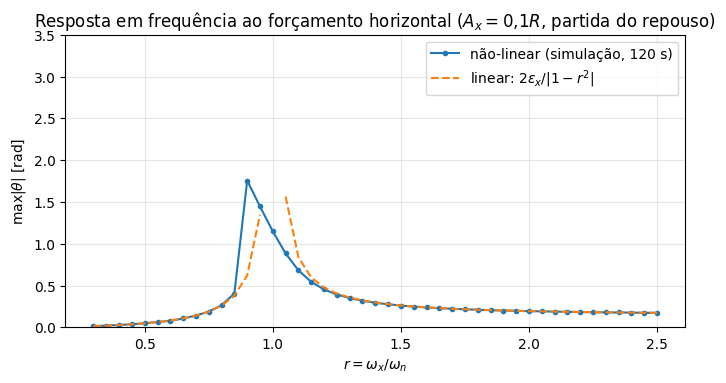

In [13]:
rs = np.linspace(0.3, 2.5, 45)
maxs = []
for r_ in rs:
    p = parametros(Ax=0.1*R_num, wx=r_*wn_num)
    t_, th_, om_ = simular(p, theta0=0.0, omega0=0.0, t_final=120.0, dt=0.02)
    maxs.append(np.max(np.abs(th_)))
ex_lin = (R_num/e_num - 1)*0.1*R_num*(rs*wn_num)**2/g_num
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(rs, maxs, "o-", ms=3, label="não-linear (simulação, 120 s)")
with np.errstate(divide="ignore"):
    ax.plot(rs, 2*ex_lin/np.abs(1 - rs**2), "--", label=r"linear: $2\epsilon_x/|1-r^2|$")
ax.set_ylim(0, 3.5); ax.set_xlabel(r"$r=\omega_x/\omega_n$"); ax.set_ylabel(r"$\max|\theta|$ [rad]")
ax.set_title("Resposta em frequência ao forçamento horizontal ($A_x=0{,}1R$, partida do repouso)"); ax.legend(); plt.show()

### (b) Crescimento exponencial na ressonância paramétrica principal e saturação não-linear

Excitação vertical em $\omega_y=2\omega_n$ com perturbação inicial minúscula ($\theta_0=10^{-3}$ rad) e diferentes amplitudes $A_y$ (isto é, diferentes $\epsilon_y$).
A taxa de crescimento inicial é comparada com a prevista pelos multiplicadores de Floquet da equação de Mathieu; a saturação ocorre quando a amplitude
é grande o bastante para a frequência não-linear sair da faixa de instabilidade.

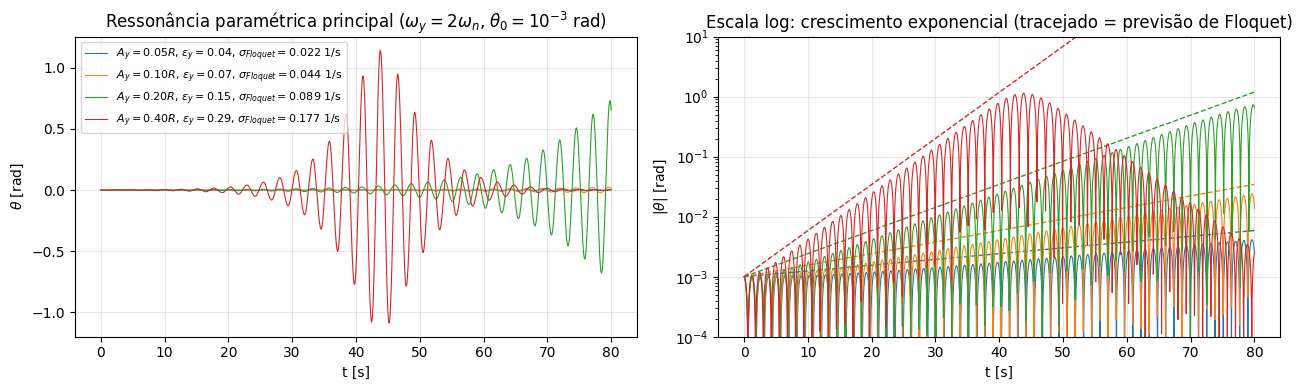

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for Ay_frac in [0.05, 0.10, 0.20, 0.40]:
    p = parametros(Ay=Ay_frac*R_num, wy=2*wn_num)
    ey = p["Ay"]*p["wy"]**2/g_num
    mu1, T1 = floquet_mathieu(np.array([2.0]), np.array([ey])); sig = np.log(mu1[0])/T1[0]*wn_num
    t_, th_, om_ = simular(p, theta0=1e-3, omega0=0.0, t_final=80.0, dt=0.02)
    l, = axs[0].plot(t_, th_, lw=0.8, label=rf"$A_y={Ay_frac:.2f}R$, $\epsilon_y={ey:.2f}$, $\sigma_{{Floquet}}={sig:.3f}$ 1/s")
    axs[1].semilogy(t_, np.abs(th_) + 1e-12, lw=0.8, color=l.get_color())
    axs[1].semilogy(t_, 1e-3*np.exp(sig*t_), "--", lw=1, color=l.get_color())
axs[0].set_xlabel("t [s]"); axs[0].set_ylabel(r"$\theta$ [rad]"); axs[0].set_title(r"Ressonância paramétrica principal ($\omega_y=2\omega_n$, $\theta_0=10^{-3}$ rad)")
axs[0].legend(fontsize=8)
axs[1].set_xlabel("t [s]"); axs[1].set_ylabel(r"$|\theta|$ [rad]"); axs[1].set_ylim(1e-4, 10); axs[1].set_title("Escala log: crescimento exponencial (tracejado = previsão de Floquet)")
plt.tight_layout(); plt.show()

### (c) O outro lado da equação de Mathieu: estabilização paramétrica da posição invertida (pêndulo de Kapitza)

Em torno de $\theta=\pi$ a equação linearizada é $\ddot\varphi-\lambda^2\,(1+\ddot y_P/g)\,\varphi=0$, com $\lambda^2=2ge/(R(3R+4e))=g/\ell'$.
Para vibração vertical rápida ($\omega_y\gg\lambda$) a teoria de Kapitza prevê que a posição invertida se torna **estável** se $(A_y\omega_y)^2>2g\ell'$.
Testa-se essa previsão partindo de $\theta_0=\pi+0{,}05$ rad com e sem a vibração (o ímã garante o contato mesmo com $\epsilon_y\gg1$).

comprimento equivalente invertido l' = 2.850 m;  critério de Kapitza: A_y*omega_y > 7.47 m/s


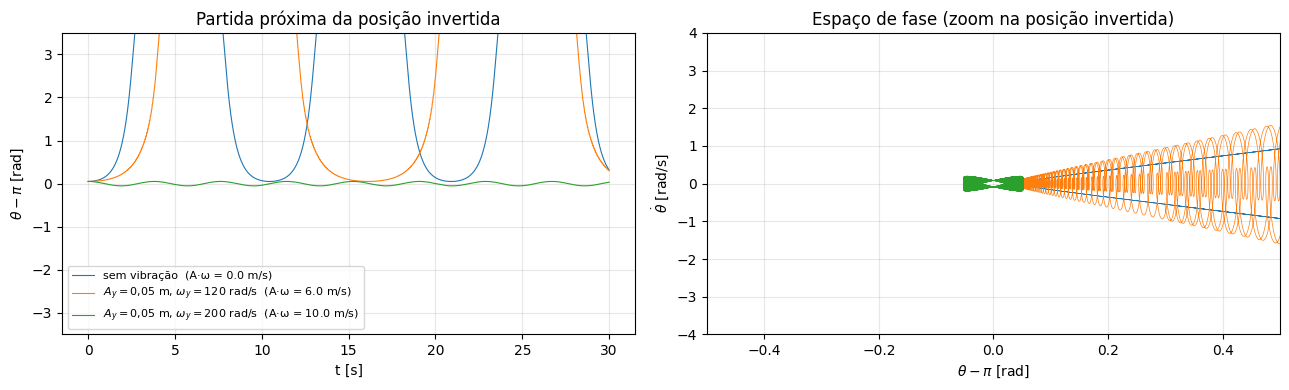

In [15]:
lam2 = 2*g_num*e_num/(R_num*(3*R_num + 4*e_num)); l_inv = g_num/lam2
v_crit = np.sqrt(2*g_num*l_inv)
print(f"comprimento equivalente invertido l' = {l_inv:.3f} m;  critério de Kapitza: A_y*omega_y > {v_crit:.2f} m/s")

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for Ay_, wy_, rot in [(0.0, 0.0, "sem vibração"), (0.05, 120.0, r"$A_y=0{,}05$ m, $\omega_y=120$ rad/s"), (0.05, 200.0, r"$A_y=0{,}05$ m, $\omega_y=200$ rad/s")]:
    p = parametros(Ay=Ay_, wy=wy_)
    t_, th_, om_ = simular(p, theta0=np.pi + 0.05, omega0=0.0, t_final=30.0, dt=0.002)
    axs[0].plot(t_, th_ - np.pi, lw=0.8, label=f"{rot}  (A·ω = {Ay_*wy_:.1f} m/s)")
    axs[1].plot(th_ - np.pi, om_, lw=0.5)
axs[0].set_ylim(-3.5, 3.5); axs[0].set_xlabel("t [s]"); axs[0].set_ylabel(r"$\theta-\pi$ [rad]"); axs[0].set_title("Partida próxima da posição invertida"); axs[0].legend(fontsize=8)
axs[1].set_xlim(-0.5, 0.5); axs[1].set_ylim(-4, 4); axs[1].set_xlabel(r"$\theta-\pi$ [rad]"); axs[1].set_ylabel(r"$\dot\theta$ [rad/s]"); axs[1].set_title("Espaço de fase (zoom na posição invertida)")
plt.tight_layout(); plt.show()

**Observações da exploração.**

* A curva de resposta em frequência tem o pico característico perto de $r=1$; longe da ressonância a simulação não-linear segue a previsão linear, e perto
  dela a amplitude satura pelo mecanismo de dessintonia. Como o período cresce com a amplitude (sistema "amolecedor"), o pico não-linear se **inclina para
  a esquerda** ($r\approx0{,}9$) e a curva apresenta um salto abrupto — assinatura típica de osciladores não-lineares (curva de resposta de Duffing).
  Acima de $r\approx1$ a resposta forçada muda de fase e decai com $1/r^2$.
* Na ressonância paramétrica principal o crescimento inicial é **exponencial** e a taxa medida coincide com a prevista pelo multiplicador de Floquet;
  quanto maior $\epsilon_y$, mais rápido o crescimento e maior a amplitude de saturação. Em contraste com o forçamento direto, bastou uma perturbação
  de $10^{-3}$ rad para desencadear a instabilidade — a resposta é "disparada" pela excitação paramétrica, não imposta por ela.
* A mesma excitação vertical que desestabiliza $\theta=0$ em $\omega_y\approx2\omega_n$ pode **estabilizar** $\theta=\pi$ quando é rápida e intensa
  (critério de Kapitza): com $A_y\omega_y$ acima do valor crítico o corpo oscila em torno da posição invertida em vez de cair, evidenciando que a excitação
  paramétrica altera a própria "rigidez" efetiva do sistema.